In [1]:
import sys, os, json
sys.path.insert(0, "..")
import pandas as pd, joblib
from src.features import preparer
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
os.makedirs("../models", exist_ok=True); os.makedirs("../reports", exist_ok=True)
df = pd.read_csv("../data/processed/credit_propre.csv")
X, y = preparer(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
modele = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1).fit(X_train, y_train)

AUC XGBoost : 0.951
[[5027   37]
 [ 367 1051]]


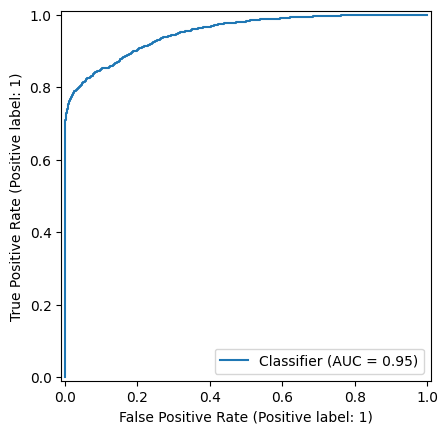

In [2]:
from sklearn.metrics import roc_auc_score, confusion_matrix, RocCurveDisplay
import matplotlib.pyplot as plt
proba = modele.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, proba)
print("AUC XGBoost :", round(auc, 3))
print(confusion_matrix(y_test, proba > 0.5))
RocCurveDisplay.from_predictions(y_test, proba)
plt.savefig("../reports/roc.png")

In [3]:
joblib.dump({"modele": modele, "colonnes": list(X.columns)}, "../models/xgb.joblib")
json.dump({"auc": round(auc, 4)}, open("../reports/metriques.json", "w"))
os.listdir("../models"), os.listdir("../reports")

(['xgb.joblib'], ['metriques.json', 'roc.png'])